# Part B · Lie Factor, in code

**Ali Afzal** · BSAI-7B-102 · Data Visualization · Week 3

Tufte's Lie Factor = (effect shown in the graphic) / (effect in the data), where effect = (final − initial)
/ initial. Honest is 1.0, and Tufte accepts 0.95–1.05. The five graphics in `case07_lie_factor.csv` are
audited from their measured ink alone. There's no need to see the pictures, which is the point of measuring.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from vizlib import PALETTE, lie_factor, lie_verdict, save_fig, style_defaults

DATA = Path("data")
CHARTS = Path("charts")
CHARTS.mkdir(exist_ok=True)
style_defaults(dpi=100)
BLUE, ORANGE, GREEN = PALETTE["series"]
GREY, INK, SOFT = PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]

lf = pd.read_csv(DATA / "case07_lie_factor.csv")
pd.set_option("display.max_colwidth", 80)
lf[["chart_id", "subject", "value_start", "value_end", "ink_start", "ink_end", "ink_unit", "ink_dimension",
    "how_the_graphic_encodes_it"]]

,chart_id,subject,value_start,value_end,ink_start,ink_end,ink_unit,ink_dimension,how_the_graphic_encodes_it
0,A,Corporate tax rate,30.0,32.0,4.0,24.0,mm,1,"Bars drawn from a 29.6% baseline, so only the tips are visible"
1,B,Federal health budget (Rs bn),40.0,60.0,1.0,1.5,x scale,2,A coin icon scaled 1.5x in BOTH height and width
2,C,Export earnings ($ bn),25.0,30.0,5.0,6.0,cm,1,Bars from zero: 5.0 cm then 6.0 cm
3,D,Air-pollution index,100.0,150.0,8.0,9.0,cm,1,Bars drawn 8.0 cm then 9.0 cm tall
4,E,City population (millions),2.0,8.0,1.0,4.0,x radius,2,A bubble whose RADIUS was set proportional to the value


## 1 · The audit table

In [2]:
rows = []
for r in lf.itertuples():
    f, d_eff, g_eff = lie_factor(r.value_start, r.value_end, r.ink_start, r.ink_end, r.ink_dimension)
    f1, _, _ = lie_factor(r.value_start, r.value_end, r.ink_start, r.ink_end, 1)
    rows.append({"chart": r.chart_id, "subject": r.subject, "data effect": f"{d_eff:+.1%}",
                 "graphic effect": f"{g_eff:+.1%}", "ink_dimension": r.ink_dimension,
                 "Lie Factor": round(f, 2), "verdict": lie_verdict(f), "LF if dimension left at 1": round(f1, 2)})
audit = pd.DataFrame(rows).set_index("chart")
audit

,subject,data effect,graphic effect,ink_dimension,Lie Factor,verdict,LF if dimension left at 1
chart,,,,,,,
A,Corporate tax rate,+6.7%,+500.0%,1,75.00,exaggerates 75.00x,75.00
B,Federal health budget (Rs bn),+50.0%,+125.0%,2,2.50,exaggerates 2.50x,1.00
C,Export earnings ($ bn),+20.0%,+20.0%,1,1.00,honest,1.00
D,Air-pollution index,+50.0%,+12.5%,1,0.25,understates (0.25),0.25
E,City population (millions),+300.0%,+1500.0%,2,5.00,exaggerates 5.00x,1.00


'charts\\b1_lie_factors.png'

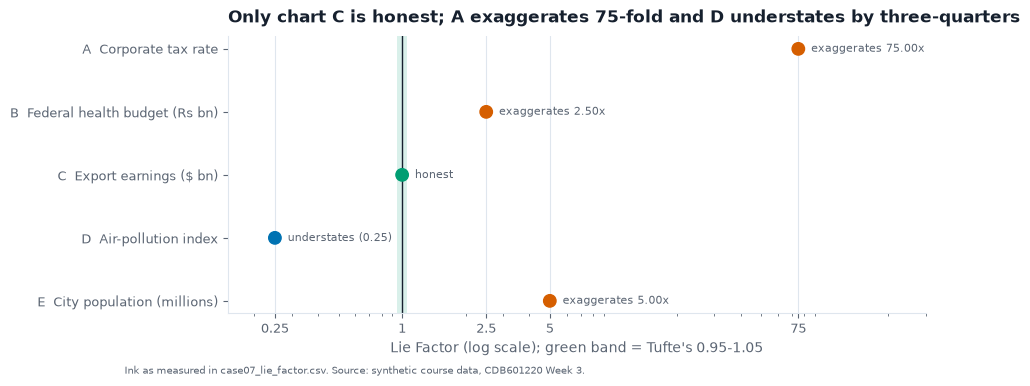

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(audit))[::-1]
cols = [GREEN if v == "honest" else (ORANGE if f > 1 else BLUE) for v, f in zip(audit.verdict, audit["Lie Factor"])]
ax.scatter(audit["Lie Factor"], y, color=cols, s=80, zorder=3)
ax.axvspan(0.95, 1.05, color=GREEN, alpha=0.15, lw=0)
ax.axvline(1, color=INK, lw=1)
ax.set_xscale("log")
ax.set_xticks([0.25, 1, 2.5, 5, 75], ["0.25", "1", "2.5", "5", "75"])
ax.set_yticks(y, [f"{c}  {s}" for c, s in zip(audit.index, audit.subject)])
for yi, f, v in zip(y, audit["Lie Factor"], audit.verdict):
    ax.text(f * 1.15, yi, v, va="center", fontsize=8, color=SOFT)
ax.set_xlim(0.15, 300)
ax.set_xlabel("Lie Factor (log scale); green band = Tufte's 0.95-1.05")
ax.grid(axis="y", visible=False)
ax.set_title("Only chart C is honest; A exaggerates 75-fold and D understates by three-quarters")
save_fig(fig, CHARTS / "b1_lie_factors.png", note="Ink as measured in case07_lie_factor.csv. Source: synthetic course data, CDB601220 Week 3.")

## 2 · One honest chart, four that aren't

**C (export earnings) is the honest one.** Bars from zero, 5.0 → 6.0 cm for 25 → 30, which is +20% shown
for +20% in the data. Lie Factor 1.00.

| Chart | What the ink is encoding instead of the value |
|---|---|
| **A** tax rate, LF 75 | The bars start at **29.6%**, so the ink encodes *value − 29.6*. A 30 → 32 rise (+6.7%) is drawn as 4 → 24 mm (+500%) |
| **B** health budget, LF 2.5 | A coin scaled 1.5× in height **and** width, so its *area* grows 2.25×. The ink encodes the value squared: +125% shown for +50% |
| **D** air pollution, LF 0.25 | Bars 8 → 9 cm for 100 → 150. The ink isn't proportional to anything, since +12.5% is shown for +50% |
| **E** city population, LF 5 | A bubble whose **radius** is proportional to the value, so its area goes as the square: 4 → 16× the area, +1,500% shown for +300% |

## 3 · Which need `ink_dimension=2`

**B and E.** Both encode the quantity as an **area** (a scaled icon and a bubble), and the eye reads the
area. Left at 1, the formula measures only the *side* or the *radius*, and both would come out a "perfect"
1.00, certifying exactly the distortion the audit exists to catch.

## 4 · The one below 1

**D, LF 0.25.** The air-pollution index rose 50%, and the bars show 12.5%. An understated chart is still
a distortion: the reader's sense of size comes from the ink, and here it says "a small increase" about a
large one. **Who benefits:** whoever is responsible for the pollution, such as the factories, the city
administration or the regulator whose plan didn't work. Exaggeration usually gets caught because it makes
a bold claim. Understatement plays down a problem, and fewer people go looking for it.

## 5 · Chart F: the dual-axis chart from Part A case 7

In [4]:
d7 = pd.read_csv(DATA / "case07_dual_axis_series.csv")
REV_AXIS, COST_AXIS = (50, 80), (40, 56)
for col, (lo, hi) in [("revenue_pkr_m", REV_AXIS), ("cost_pkr_m", COST_AXIS)]:
    v0, v1 = d7[col].iloc[0], d7[col].iloc[-1]
    f, de, ge = lie_factor(v0, v1, v0 - lo, v1 - lo, 1)
    print(f"{col:14s} on its own axis {lo}-{hi}: data {de:+.1%}, ink above the axis floor {ge:+.0%}, LF {f:.1f}")
print("\nmargin (revenue - cost), PKR m:", (d7.revenue_pkr_m - d7.cost_pkr_m).tolist())

revenue_pkr_m  on its own axis 50-80: data +50.0%, ink above the axis floor +1300%, LF 26.0
cost_pkr_m     on its own axis 40-56: data +20.5%, ink above the axis floor +225%, LF 11.0

margin (revenue - cost), PKR m: [8, 12, 14, 17, 20, 25]


**The claim has no Lie Factor, and that's the finding.** The formula assumes **one** quantitative scale on
which ink is proportional to value. Each line *on its own* can be scored: revenue drawn on its 50–80 axis
has an LF of 26, and cost on its 40–56 axis an LF of 11, both because their floors aren't zero. But the
published claim, "cost was above revenue until May", isn't about either line's growth. It's about where
one line sits *relative to the other*. On a twin axis that position comes from two independently chosen
ranges, so there's no "effect shown" that corresponds to anything in the data. Move either axis and the
crossing moves or disappears. You can't divide by an effect the chart made up.

**What the data actually shows:** revenue was above cost in **every** month, and the margin grew 8 → 12 →
14 → 17 → 20 → 25 PKR m. ShaheenGo was never at a loss. Both series are in PKR millions, so one axis was
always possible. That's the reason the dual-axis ban has no exceptions.